# Previsão da produção eólica (*Wind*)

Componente: **Produção Eólica (`capacity_factor`)** \
Período: **1 ano completo (8 760 registos horários)** \
Dataset: *University campus buildings electrical and thermal demand and generation* (Zenodo, projeto E-LAND).

## Configuração e carregamento dos dados
O ficheiro CSV (`wind.csv` / `Wind.csv`) é lido a partir da pasta atual ou de `dataset/UVTgv_OD/production/`, a partir da raiz do repositório. \
O ficheiro contém uma única coluna (`capacity_factor`) com **8 760 registos horários** (365 dias × 24 horas), sem coluna explícita de data/hora. Reconstrói-se o índice horário contínuo para um ano padrão não bissexto (`2021-01-01 00:00` a `2021-12-31 23:00`, conforme a documentação do dataset E-LAND), mantendo `hora`, `dia_semana`, `mes`, `fim_semana`, `dia_ano` e `hora_ano`.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

# Procura wind.csv ou Wind.csv na pasta atual ou na estrutura do repositório
candidatos = [
    Path("wind.csv"),
    Path("Wind.csv"),
    *(p / "dataset/UVTgv_OD/production/Wind.csv" for p in (Path.cwd(), *Path.cwd().parents)),
    *(p / "dataset/UVTgv_OD/production/wind.csv" for p in (Path.cwd(), *Path.cwd().parents)),
]
ficheiro_wind = next((p for p in candidatos if p.is_file()), None)
if ficheiro_wind is None:
    raise FileNotFoundError("Coloca o ficheiro wind.csv (ou Wind.csv) na pasta do notebook ou na pasta dataset/UVTgv_OD/production/.")

df_raw = pd.read_csv(ficheiro_wind, skip_blank_lines=False)
col_alvo = "capacity_factor" if "capacity_factor" in df_raw.columns else df_raw.columns[0]
s = pd.to_numeric(df_raw[col_alvo], errors="coerce")

horas = pd.date_range("2021-01-01 00:00", periods=len(s), freq="h")
d = pd.DataFrame({"capacity_factor": s.values}, index=horas)
d.index.name = "data_hora"

d["hora"] = d.index.hour
d["dia_semana"] = d.index.dayofweek          # 0 = segunda
d["mes"] = d.index.month
d["fim_semana"] = d["dia_semana"] >= 5
d["dia_ano"] = d.index.dayofyear
d["hora_ano"] = (d["dia_ano"] - 1) * 24 + d["hora"]

d.head()

,capacity_factor,hora,dia_semana,mes,fim_semana,dia_ano,hora_ano
data_hora,,,,,,,
2021-01-01 00:00:00,0.000000,0,4,1,False,1,0
2021-01-01 01:00:00,0.000000,1,4,1,False,1,1
2021-01-01 02:00:00,0.054392,2,4,1,False,1,2
2021-01-01 03:00:00,0.000000,3,4,1,False,1,3
2021-01-01 04:00:00,0.048091,4,4,1,False,1,4


In [1]:
%pip install --upgrade matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\DELL\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


---
# 4.1. Análise exploratória dos dados

## 4.1.1. Número de registos
O ficheiro anual contém **8 760 registos horários** (365 dias × 24 h), correspondentes a um ano completo sem dia 29 de fevereiro.

In [3]:
print("Nº total de registos:", len(d))
print("Início da série:", d.index.min(), "| Fim da série:", d.index.max())
print(d.groupby("mes").size().rename("registos").to_frame().T.to_string())

Nº total de registos: 8760
Início da série: 2021-01-01 00:00:00 | Fim da série: 2021-12-31 23:00:00
mes        1    2    3    4    5    6    7    8    9    10   11   12
registos  744  672  744  720  744  720  744  744  720  744  720  744


## 4.1.2. Variável a prever e unidades
- **Variável a prever:** fator de capacidade horário da instalação eólica (`capacity_factor`).
- **Unidade:** grandeza adimensional (fração da potência nominal instalada, no intervalo $[0, 1]$).

## 4.1.3. Distribuição e variabilidade
Estatísticas descritivas do fator de capacidade (inclui o coeficiente de variação, `CV`, e a assimetria, `skew`), seguidas dos histogramas (todas as observações vs. apenas observações estritamente positivas, para evitar que o elevado número de zeros comprima a escala) e do diagrama de caixa.

In [4]:
cf = d["capacity_factor"]
cf_pos = cf[cf > 0]

resumo = pd.DataFrame({
    "Todas as horas": cf.describe(),
    "Apenas > 0": cf_pos.describe(),
}).T
resumo["CV"] = [cf.std() / cf.mean(), cf_pos.std() / cf_pos.mean()]
resumo["skew"] = [cf.skew(), cf_pos.skew()]
resumo.round(4)

,count,mean,std,min,25%,50%,75%,max,CV,skew
Todas as horas,8760.0,0.0236,0.0636,0.0000,0.0000,0.0000,0.0000,0.8721,2.6900,4.5001
Apenas > 0,1978.0,0.1047,0.0971,0.0342,0.0404,0.0648,0.1337,0.8721,0.9273,2.5666


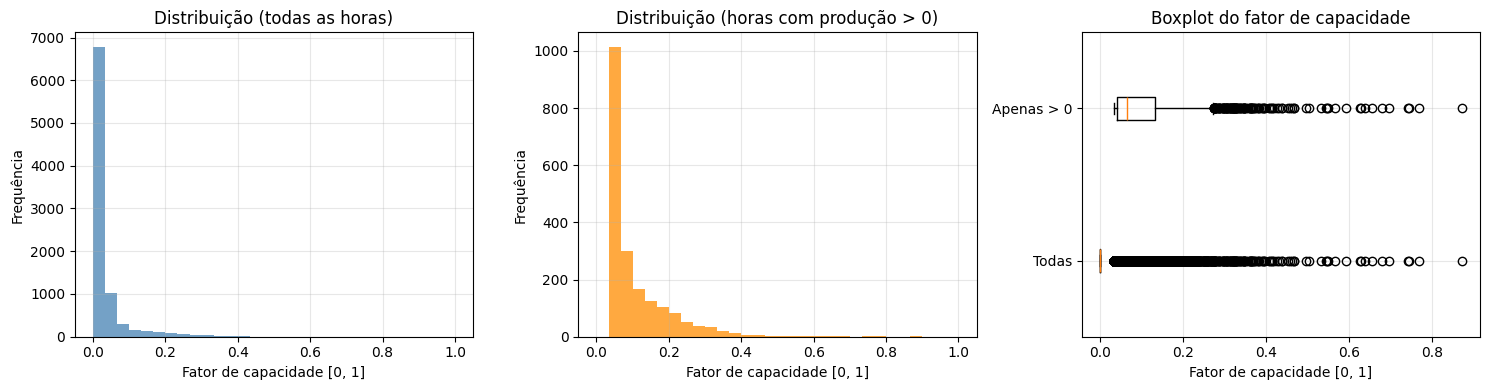

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(cf.dropna(), bins=30, range=(0, 1), alpha=0.75, color="steelblue")
ax[0].set(title="Distribuição (todas as horas)", xlabel="Fator de capacidade [0, 1]", ylabel="Frequência")

ax[1].hist(cf_pos.dropna(), bins=30, range=(0, 1), alpha=0.75, color="darkorange")
ax[1].set(title="Distribuição (horas com produção > 0)", xlabel="Fator de capacidade [0, 1]", ylabel="Frequência")

ax[2].boxplot([cf.dropna(), cf_pos.dropna()], vert=False)
ax[2].set_yticklabels(["Todas", "Apenas > 0"])
ax[2].set(title="Boxplot do fator de capacidade", xlabel="Fator de capacidade [0, 1]")

plt.tight_layout()
plt.show()

## 4.1.4. Valores em falta ou inconsistentes
Verificação de valores em falta (`NaN`), valores fora do domínio físico $[0, 1]$, registos iguais a zero (`== 0`), datas duplicadas, regularidade da frequência (1 h) e *outliers* (regra do IQR aplicada tanto à série global como às horas com produção positiva).

In [6]:
x = d["capacity_factor"]
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
n_out_global = ((x > q3 + 1.5 * iqr) | (x < q1 - 1.5 * iqr)).sum()

x_pos = x[x > 0]
q1_p, q3_p = x_pos.quantile([0.25, 0.75])
iqr_p = q3_p - q1_p
n_out_pos = ((x_pos > q3_p + 1.5 * iqr_p) | (x_pos < q1_p - 1.5 * iqr_p)).sum()

verificacao = pd.DataFrame([{
    "em falta": int(x.isna().sum()),
    "< 0 ou > 1": int(((x < 0) | (x > 1)).sum()),
    "== 0 (calmaria)": int((x == 0).sum()),
    "% zeros": round(100 * (x == 0).mean(), 1),
    "duplicados": int(d.index.duplicated().sum()),
    "saltos ≠ 1h": int((d["hora_ano"].diff().dropna() != 1).sum()),
    "outliers IQR (global)": int(n_out_global),
    "outliers IQR (> 0)": int(n_out_pos),
}])
verificacao

,em falta,< 0 ou > 1,== 0 (calmaria),% zeros,duplicados,saltos ≠ 1h,outliers IQR (global),outliers IQR (> 0)
0,0,0,6782,77.4,0,0,1978,123


In [7]:
# Análise das sequências contínuas com capacity_factor == 0 (períodos sem vento suficiente)
z = d[d["capacity_factor"] == 0]
print(f"Total de horas com capacity_factor == 0: {len(z)} ({100 * len(z) / len(d):.1f}%)")
if len(z) > 0:
    print("\nDistribuição mensal das horas nulas:")
    print(z.groupby("mes").size().rename("horas").to_frame().T.to_string())

    grupo = (z.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
    blocos = sorted(
        z.groupby(grupo.values).apply(lambda b: (b.index.min(), b.index.max(), len(b))),
        key=lambda t: -t[2],
    )[:5]
    print("\nMaiores sequências contínuas de produção nula:")
    for ini, fim, n in blocos:
        print(f"   {ini} -> {fim} ({n} h)")

Total de horas com capacity_factor == 0: 6782 (77.4%)

Distribuição mensal das horas nulas:
mes     1    2    3    4    5    6    7    8    9    10   11   12
horas  541  514  486  423  503  578  657  687  611  548  598  636

Maiores sequências contínuas de produção nula:
   2021-08-04 09:00:00 -> 2021-08-12 13:00:00 (197 h)
   2021-08-15 07:00:00 -> 2021-08-21 16:00:00 (154 h)
   2021-02-11 04:00:00 -> 2021-02-16 12:00:00 (129 h)
   2021-07-05 06:00:00 -> 2021-07-10 06:00:00 (121 h)
   2021-06-19 16:00:00 -> 2021-06-24 14:00:00 (119 h)


## 4.1.5. Evolução ao longo do tempo
Série horária completa ao longo do ano com média móvel de 7 dias, acompanhada de um detalhe das primeiras 168 horas (primeira semana) para observar a persistência dos eventos de vento.

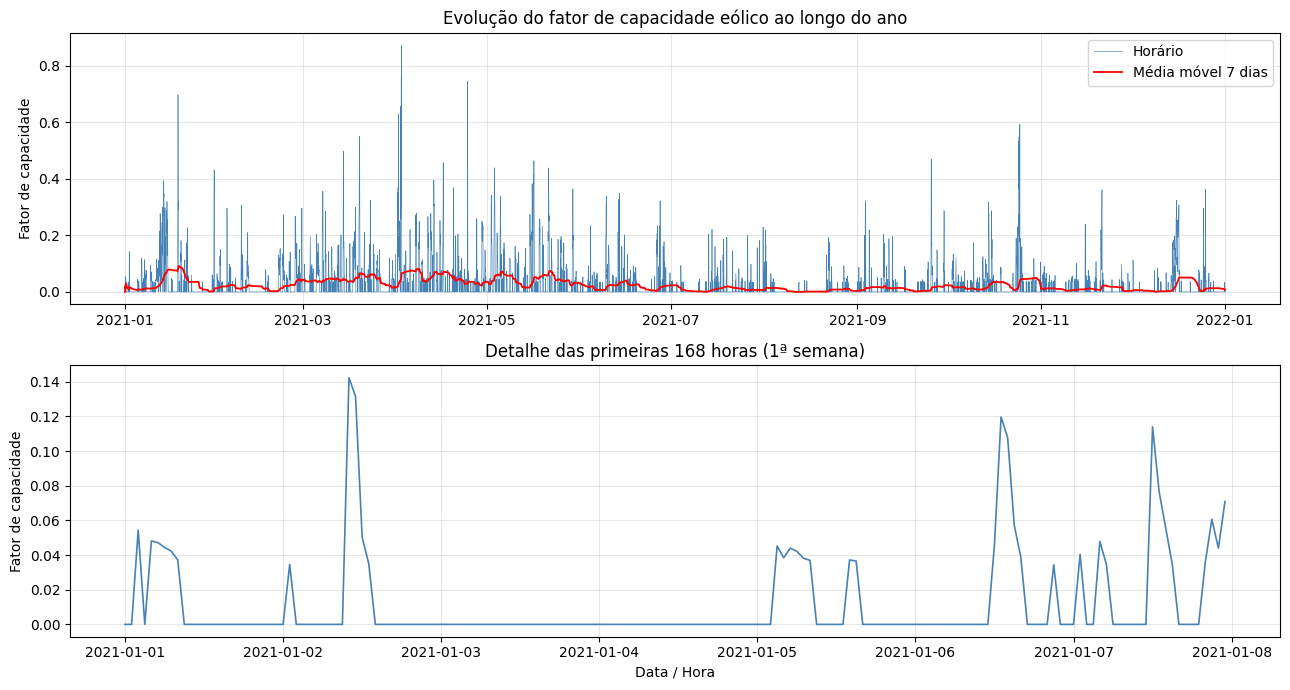

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))

s = d["capacity_factor"]
ax[0].plot(s, lw=0.45, color="steelblue", label="Horário")
ax[0].plot(s.rolling(24 * 7, min_periods=1).mean(), color="red", lw=1.3, label="Média móvel 7 dias")
ax[0].set(title="Evolução do fator de capacidade eólico ao longo do ano", ylabel="Fator de capacidade")
ax[0].legend(loc="upper right")

ax[1].plot(s.iloc[:168], lw=1.2, color="steelblue")
ax[1].set(title="Detalhe das primeiras 168 horas (1ª semana)", xlabel="Data / Hora", ylabel="Fator de capacidade")

plt.tight_layout()
plt.show()

## 4.1.6. Padrões diários, semanais e sazonais
Análise do perfil horário médio (dia útil vs. fim de semana), médias por dia da semana e por mês, mapas de calor (*heatmaps*) `hora × dia da semana` e `hora × mês`, e tabela de autocorrelação para diferentes desfasamentos (*lags*).

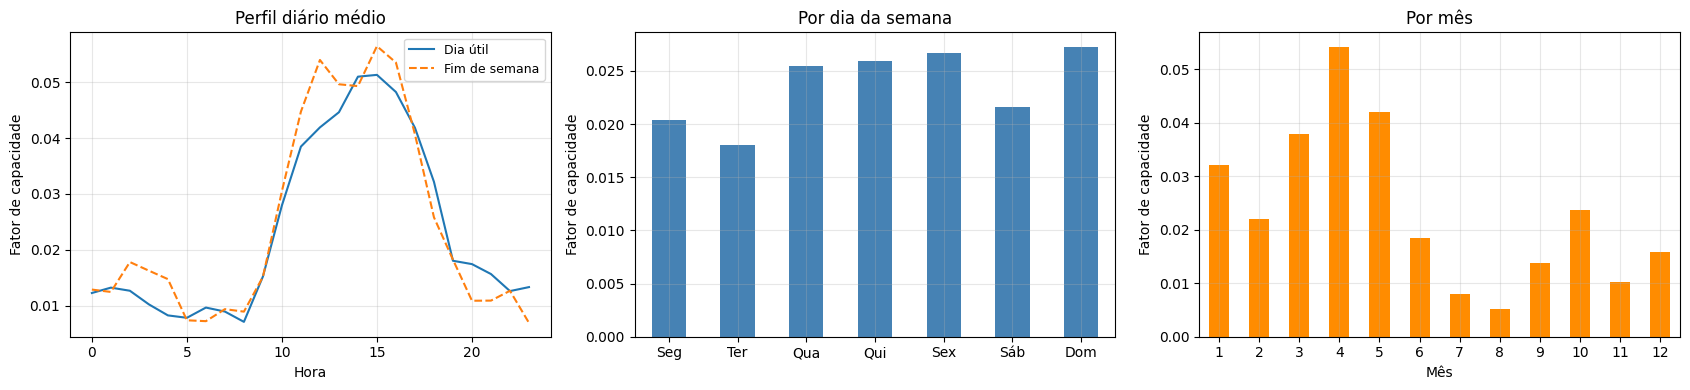

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# 1. Perfil diário médio: dia útil vs fim de semana
p = d.groupby(["hora", "fim_semana"])["capacity_factor"].mean().unstack()
ax[0].plot(p.index, p[False], label="Dia útil")
ax[0].plot(p.index, p[True], ls="--", label="Fim de semana")
ax[0].set(title="Perfil diário médio", xlabel="Hora", ylabel="Fator de capacidade")
ax[0].legend(fontsize=9)

# 2. Média por dia da semana
d.groupby("dia_semana")["capacity_factor"].mean().plot(kind="bar", ax=ax[1], color="steelblue", title="Por dia da semana")
ax[1].set_xticklabels(DIAS, rotation=0)
ax[1].set(xlabel="", ylabel="Fator de capacidade")

# 3. Média por mês
d.groupby("mes")["capacity_factor"].mean().plot(kind="bar", ax=ax[2], color="darkorange", title="Por mês")
ax[2].set_xticklabels(range(1, 13), rotation=0)
ax[2].set(xlabel="Mês", ylabel="Fator de capacidade")

plt.tight_layout()
plt.show()

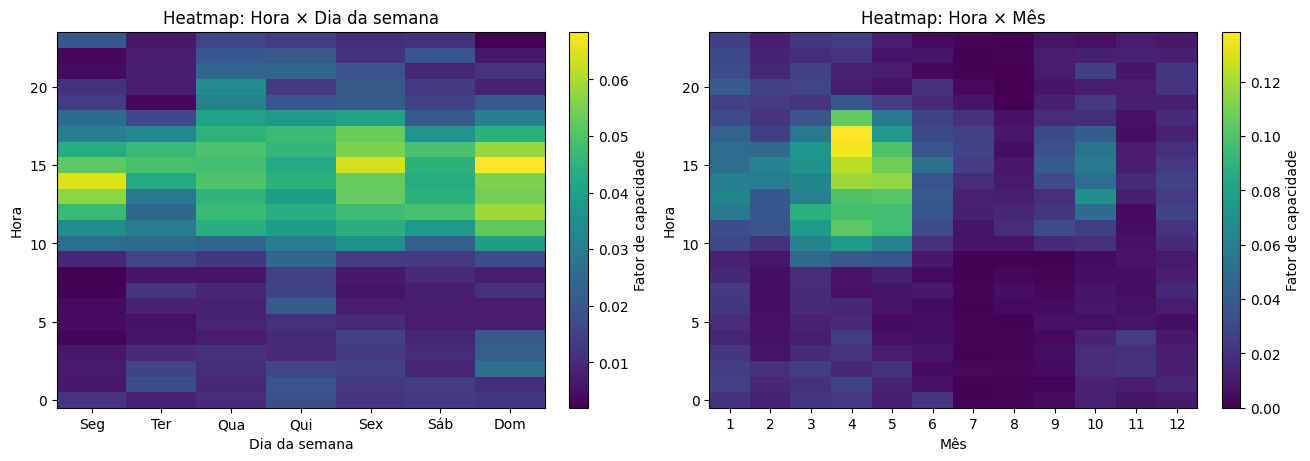

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

pv_sem = d.pivot_table(index="hora", columns="dia_semana", values="capacity_factor", aggfunc="mean")
im0 = ax[0].imshow(pv_sem, aspect="auto", cmap="viridis", origin="lower")
ax[0].set(title="Heatmap: Hora × Dia da semana", xlabel="Dia da semana", ylabel="Hora")
ax[0].set_xticks(range(7))
ax[0].set_xticklabels(DIAS)
ax[0].grid(False)
fig.colorbar(im0, ax=ax[0], label="Fator de capacidade")

pv_mes = d.pivot_table(index="hora", columns="mes", values="capacity_factor", aggfunc="mean")
im1 = ax[1].imshow(pv_mes, aspect="auto", cmap="viridis", origin="lower")
ax[1].set(title="Heatmap: Hora × Mês", xlabel="Mês", ylabel="Hora")
ax[1].set_xticks(range(12))
ax[1].set_xticklabels(range(1, 13))
ax[1].grid(False)
fig.colorbar(im1, ax=ax[1], label="Fator de capacidade")

plt.show()

In [11]:
rotulos = {
    1:   "hora anterior",
    2:   "2 h antes",
    3:   "3 h antes",
    6:   "6 h antes",
    12:  "12 h antes",
    24:  "mesma hora, dia anterior",
    48:  "mesma hora, 2 dias antes",
    168: "mesma hora, semana anterior",
}
ac = pd.Series(
    {rot: round(d["capacity_factor"].autocorr(l), 3) for l, rot in rotulos.items()},
    name="Autocorrelação",
)
ac.to_frame()

,Autocorrelação
hora anterior,0.795
2 h antes,0.630
3 h antes,0.506
6 h antes,0.254
12 h antes,0.096
"mesma hora, dia anterior",0.242
"mesma hora, 2 dias antes",0.155
"mesma hora, semana anterior",0.096


## 4.1.7. Períodos de produção elevada ou reduzida
Identificação dos dias com maior e menor fator de capacidade médio diário, bem como das horas e meses de pico e de mínimo médio.

In [12]:
diario = d["capacity_factor"].resample("D").mean().dropna()
mh = d.groupby("hora")["capacity_factor"].mean()
mm = d.groupby("mes")["capacity_factor"].mean()

print("Dias de maior produção média :", ", ".join(f"{i.date()} ({v:.3f})" for i, v in diario.nlargest(5).items()))
print("Dias de menor produção média :", ", ".join(f"{i.date()} ({v:.3f})" for i, v in diario.nsmallest(5).items()))
print(f"Hora de pico médio: {mh.idxmax()}h ({mh.max():.3f}) | Hora de mínimo médio: {mh.idxmin()}h ({mh.min():.3f})")
print(f"Mês de maior produção: {mm.idxmax()} ({mm.max():.3f}) | Mês de menor produção: {mm.idxmin()} ({mm.min():.3f})")

Dias de maior produção média : 2021-04-02 (0.265), 2021-10-24 (0.229), 2021-01-13 (0.191), 2021-05-16 (0.178), 2021-01-18 (0.155)
Dias de menor produção média : 2021-01-03 (0.000), 2021-01-04 (0.000), 2021-01-17 (0.000), 2021-01-24 (0.000), 2021-01-25 (0.000)
Hora de pico médio: 15h (0.053) | Hora de mínimo médio: 8h (0.008)
Mês de maior produção: 4 (0.054) | Mês de menor produção: 8 (0.005)


## 4.1.8. Conclusões da análise exploratória
- **Dados e qualidade:** 8 760 registos horários no intervalo adimensional $[0, 1]$, sem valores em falta, valores inválidos nem datas repetidas. As horas iguais a `0` correspondem a períodos de calmaria (velocidade do vento abaixo do limiar de arranque da turbina) e são mantidas como observações reais.
- **Distribuição:** fortemente assimétrica à direita, concentrada em valores baixos/moderados, com episódios pontuais de vento forte a aproximar-se da potência nominal (`1.0`).
- **Ausência de ciclo semanal humano:** ao contrário do consumo elétrico dos edifícios, o fator de capacidade eólico não apresenta diferença relevante entre dias úteis e fins de semana, por depender exclusivamente de fenómenos atmosféricos.
- **Sazonalidade e ciclo diurno:** observa-se variação mensal clara (meses mais ventosos vs. meses mais calmos) e uma ligeira modulação ao longo das 24 horas associada ao aquecimento térmico diurno.
- **Autocorrelação:** muito elevada nos primeiros desfasamentos (`lag 1h`, `2h`, `3h`), refletindo a inércia das massas de ar, e substancialmente mais baixa a `24h` e `168h`.

---
# 4.2. Preparação dos dados

## 4.2.1. Verificação e ordenação temporal dos registos
Garante-se que a série horária está estritamente ordenada no tempo e sem carimbos temporais repetidos.

In [13]:
dp = d.copy().sort_index(kind="stable")
s = dp["capacity_factor"]

pd.DataFrame([{
    "registos": len(s),
    "ordem crescente": s.index.is_monotonic_increasing,
    "sem datas repetidas": s.index.is_unique,
    "início": s.index.min(),
    "fim": s.index.max(),
}])

,registos,ordem crescente,sem datas repetidas,início,fim
0,8760,True,True,2021-01-01,2021-12-31 23:00:00


## 4.2.2. Tratamento de valores em falta ou inválidos
- Os valores iguais a `0` são **fisicamente válidos** (vento abaixo da velocidade de arranque da turbina) e são preservados na série.
- Caso existam eventuais valores em falta (`NaN`) ou fora do intervalo físico $[0, 1]$, são marcados como inválidos. Para não introduzir informação futura (*data leakage*), não se interpola através de janelas longas: eventuais registos inválidos são removidos após a criação dos *lags* (mantendo o registo original em `cf_original`).

In [14]:
dp["cf_original"] = dp["capacity_factor"]
invalido = dp["cf_original"].isna() | ~dp["cf_original"].between(0, 1)

# Mantém todos os valores válidos em [0, 1], incluindo os zeros físicos de calmaria
dp["capacity_factor"] = dp["cf_original"].where(~invalido)

print("Registos inválidos ou em falta:", int(invalido.sum()))
print("Zeros preservados (calmaria):", int((dp["capacity_factor"] == 0).sum()))

Registos inválidos ou em falta: 0
Zeros preservados (calmaria): 6782


## 4.2.3. Identificação de valores atípicos
Compara-se cada observação com o **padrão típico da sua hora e do seu mês** (média e desvio padrão por `mes` e `hora`), assinalando como atípicos (`atipico = True`) os registos que se afastam mais de `LIMIAR_DP = 3` desvios padrão.

Tal como nos edifícios, os valores atípicos são **apenas assinalados e não removidos**, pois representam rajadas ou eventos meteorológicos reais que os modelos de previsão têm de enfrentar.

Nº de atípicos (> 3 DP): 280 (3.20%)


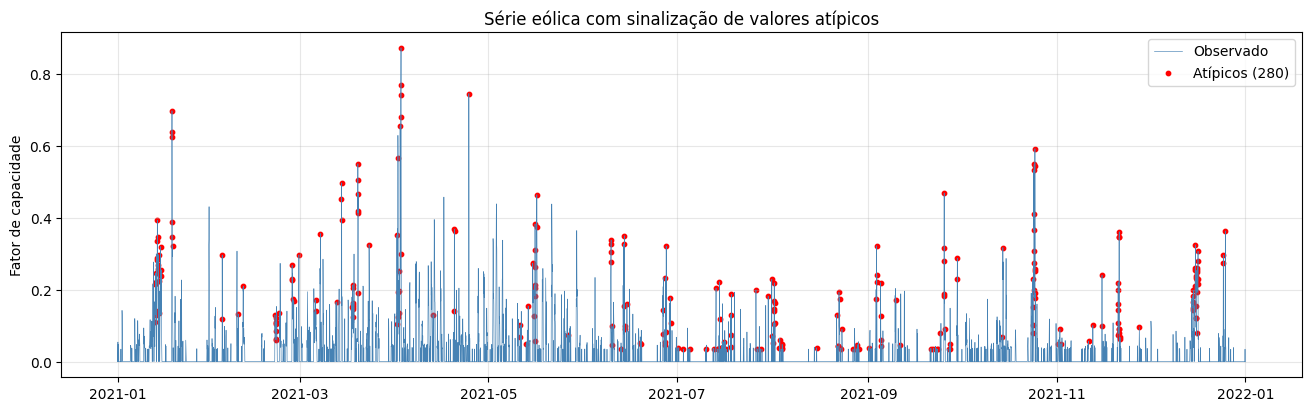

In [15]:
LIMIAR_DP = 3
chave = [dp["mes"], dp["hora"]]
media = dp.groupby(chave)["capacity_factor"].transform("mean")
desvio_padrao = dp.groupby(chave)["capacity_factor"].transform("std")

dp["desvio_z"] = (dp["capacity_factor"] - media) / desvio_padrao.replace(0, np.nan)
dp["atipico"] = dp["desvio_z"].abs() > LIMIAR_DP

print(f"Nº de atípicos (> {LIMIAR_DP} DP): {dp['atipico'].sum()} ({100 * dp['atipico'].mean():.2f}%)")

fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
ax.plot(dp.index, dp["capacity_factor"], lw=0.45, color="steelblue", label="Observado")
at = dp[dp["atipico"]]
ax.scatter(at.index, at["capacity_factor"], s=10, color="red", label=f"Atípicos ({len(at)})")
ax.set(title="Série eólica com sinalização de valores atípicos", ylabel="Fator de capacidade")
ax.legend(loc="upper right")
plt.show()

## 4.2.4. Verificação da periodicidade dos registos
Confirma-se que o intervalo entre registos consecutivos é sempre exatamente **1 hora** ao longo de todo o ano (365 dias × 24 horas).

In [16]:
dif = dp["hora_ano"].diff().dropna()

pd.DataFrame([{
    "intervalos distintos": dif.nunique(),
    "intervalo (h)": int(dif.iloc[0]),
    "saltos ≠ 1h": int((dif != 1).sum()),
    "total de dias": dp.index.normalize().nunique(),
}])

,intervalos distintos,intervalo (h),saltos ≠ 1h,total de dias
0,1,1,0,365


## 4.2.5. Criação de variáveis temporais e justificação
Cada linha representa **a hora a prever (`t`)** e utiliza exclusivamente informação **anterior** a esse instante (sem *data leakage*):

- **Hora do dia (`hora_relogio_y`, `hora_relogio_x`):** codificação cíclica ($\sin(2\pi h/24)$ e $\cos(2\pi h/24)$) para garantir continuidade entre as 23h e as 00h e captar a brisa térmica diurna.
- **Mês do ano (`mes_sin`, `mes_cos`):** codificação cíclica ($\sin(2\pi (m-1)/12)$ e $\cos(2\pi (m-1)/12)$) para representar a sazonalidade anual sem salto artificial entre dezembro e janeiro.
- **Desfasamentos recentes (`cf_hora_anterior`, `cf_2h_antes`, `cf_3h_antes`):** captam a forte persistência sinóptica e a tendência imediata (aceleração/desaceleração do vento).
- **Desfasamento diário (`cf_dia_anterior`):** mesma hora do dia anterior (`lag 24h`), captando o ciclo diurno.
- **Exclusão de `dia_semana` / `fim_de_semana`:** justificada pela análise exploratória — como o vento é um fenómeno meteorológico, o dia da semana não tem significado físico nem poder explicativo.

In [17]:
# Codificação cíclica da hora e do mês
dp["hora_relogio_y"] = np.sin(2 * np.pi * dp["hora"] / 24)
dp["hora_relogio_x"] = np.cos(2 * np.pi * dp["hora"] / 24)
dp["mes_sin"] = np.sin(2 * np.pi * (dp["mes"] - 1) / 12)
dp["mes_cos"] = np.cos(2 * np.pi * (dp["mes"] - 1) / 12)

# Desfasamentos históricos (apenas valores passados)
lags = {
    1: "cf_hora_anterior",
    2: "cf_2h_antes",
    3: "cf_3h_antes",
    24: "cf_dia_anterior",
}
for k, nome in lags.items():
    dp[nome] = dp["capacity_factor"].shift(k)

FEATURES_BASE = [
    "hora_relogio_y",
    "hora_relogio_x",
    "mes_sin",
    "mes_cos",
    "cf_hora_anterior",
    "cf_2h_antes",
    "cf_3h_antes",
    "cf_dia_anterior",
]

print("Linhas iniciais sem histórico completo (primeiras 24h):", int(dp["cf_dia_anterior"].isna().sum()))

# Correlação de Pearson entre o fator de capacidade e cada variável candidata
x_corr = dp.dropna(subset=FEATURES_BASE)
corr_df = (
    x_corr[["capacity_factor"] + FEATURES_BASE]
    .corr()["capacity_factor"]
    .drop("capacity_factor")
    .rename("Correlação de Pearson")
    .to_frame()
    .round(3)
)
corr_df

Linhas iniciais sem histórico completo (primeiras 24h): 24


,Correlação de Pearson
hora_relogio_y,-0.134
hora_relogio_x,-0.176
mes_sin,0.164
mes_cos,0.063
cf_hora_anterior,0.795
cf_2h_antes,0.630
cf_3h_antes,0.506
cf_dia_anterior,0.242


## 4.2.6. Guardar em CSV
Exportação do conjunto de dados preparado para a pasta `dataset/final/wind_preparado.csv` (ou na pasta atual, caso não exista estrutura de repositório), pronto para a definição do problema e modelação na secção 4.3.

In [18]:
colunas = ["capacity_factor"] + FEATURES_BASE + ["cf_original", "atipico"]
dados_prontos = dp[colunas]

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dataset").exists()), Path.cwd())
pasta_final = (raiz / "dataset" / "final") if (raiz / "dataset").exists() else raiz
pasta_final.mkdir(parents=True, exist_ok=True)

caminho_saida = pasta_final / "wind_preparado.csv"
dados_prontos.to_csv(caminho_saida, index_label="data_hora")

print("Ficheiro guardado em:", caminho_saida)
print("Total de registos:", len(dados_prontos))
dados_prontos.iloc[[0, 1, 2, 3, 24, 25]].round(3)

Ficheiro guardado em: c:\Users\DELL\Downloads\Energy_Consuption_Prediction\vasco\wind_preparado.csv
Total de registos: 8760


,capacity_factor,hora_relogio_y,hora_relogio_x,mes_sin,mes_cos,cf_hora_anterior,cf_2h_antes,cf_3h_antes,cf_dia_anterior,cf_original,atipico
data_hora,,,,,,,,,,,
2021-01-01 00:00:00,0.000,0.000,1.000,0.0,1.0,NaN,NaN,NaN,NaN,0.000,False
2021-01-01 01:00:00,0.000,0.259,0.966,0.0,1.0,0.000,NaN,NaN,NaN,0.000,False
2021-01-01 02:00:00,0.054,0.500,0.866,0.0,1.0,0.000,0.0,NaN,NaN,0.054,False
2021-01-01 03:00:00,0.000,0.707,0.707,0.0,1.0,0.054,0.0,0.0,NaN,0.000,False
2021-01-02 00:00:00,0.000,0.000,1.000,0.0,1.0,0.000,0.0,0.0,0.0,0.000,False
2021-01-02 01:00:00,0.035,0.259,0.966,0.0,1.0,0.000,0.0,0.0,0.0,0.035,False


## 4.2.7. Resumo da preparação dos dados
- **Ordenação e periodicidade:** 8 760 registos horários ordenados e contínuos (intervalo constante de 1 h ao longo de 365 dias).
- **Valores em falta ou inválidos:** inexistentes; os zeros (`capacity_factor == 0`) foram mantidos por representarem períodos reais de calmaria.
- **Atípicos:** horas acima de 3 desvios padrão em relação à média da mesma hora e mês, assinaladas na coluna `atipico` sem remoção.
- **Variáveis base:** `hora_relogio_y`, `hora_relogio_x`, `mes_sin`, `mes_cos`, `cf_hora_anterior`, `cf_2h_antes`, `cf_3h_antes` e `cf_dia_anterior`. Excluíram-se variáveis de dia da semana por não influenciarem a geração eólica.
